# Muestreo e intervalos: repetir el experimento

## Objetivo
Separar dispersión de datos e incertidumbre sobre la media, y comprobar cobertura por simulación.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Distribución de la media

Generamos muestras IID de una población normal con media 10 y desviación 2. Para tamaño n, la media tiene desviación $2/\sqrt{n}$. Comparamos n=5 y n=50 con igual número de repeticiones.

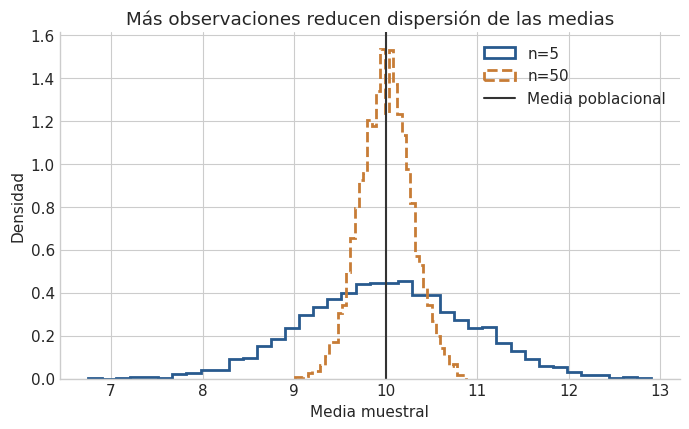

In [2]:
repeticiones=4000
fig,ax=plt.subplots()
for n,estilo in [(5,'-'),(50,'--')]:
    medias=rng.normal(10,2,(repeticiones,n)).mean(axis=1)
    ax.hist(medias,bins=40,density=True,histtype='step',linewidth=2,linestyle=estilo,label=f'n={n}')
ax.axvline(10,color='#333333',label='Media poblacional')
ax.set(xlabel='Media muestral',ylabel='Densidad',title='Más observaciones reducen dispersión de las medias')
ax.legend(); plt.show()

**Lectura del resultado.** Las medias de muestras de 50 se concentran más alrededor de 10. Los individuos siguen teniendo desviación 2: aumentar n reduce incertidumbre sobre su promedio.

## 2. Cobertura de intervalos t

Con varianza desconocida y normalidad, usamos $\bar{x}\pm t_{n-1,0.975}s/\sqrt{n}$. Repetimos 4000 muestras de 25 y contamos qué intervalos contienen la media verdadera 10.

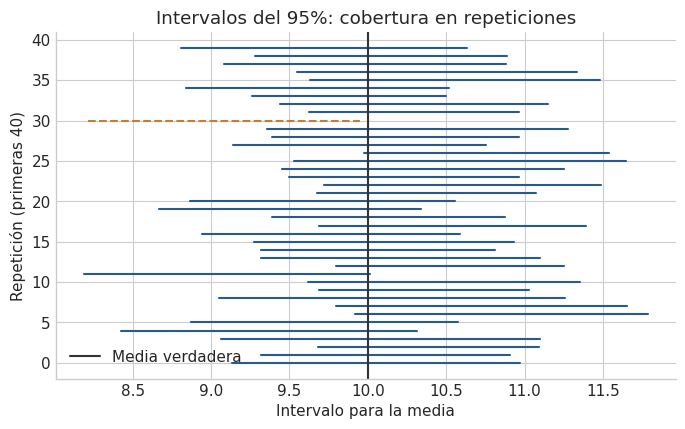

Cobertura observada: 95.325%; error Monte Carlo aproximado: 0.345%


In [3]:
n=25
muestras=rng.normal(10,2,(repeticiones,n))
centros=muestras.mean(axis=1)
anchos=stats.t.ppf(.975,n-1)*muestras.std(axis=1,ddof=1)/np.sqrt(n)
cubren=(centros-anchos<=10)&(10<=centros+anchos)
cobertura=cubren.mean()
print(f'Cobertura observada: {cobertura:.3%}; error Monte Carlo aproximado: {np.sqrt(.95*.05/repeticiones):.3%}')
fig,ax=plt.subplots()
for i in range(40):
    ax.plot([centros[i]-anchos[i],centros[i]+anchos[i]],[i,i],'-' if cubren[i] else '--',color='#285A8E' if cubren[i] else '#C77C36')
ax.axvline(10,color='#333333',label='Media verdadera')
ax.set(xlabel='Intervalo para la media',ylabel='Repetición (primeras 40)',title='Intervalos del 95%: cobertura en repeticiones')
ax.legend(); plt.show()

**Lectura del resultado.** Algunos intervalos no cubren 10. El 95% describe el procedimiento repetido, no una garantía por intervalo. La cobertura simulada fluctúa; las hipótesis son normalidad e independencia.

## Practica antes de ver la solución

Si cuadruplicas n y mantienes la misma dispersión, ¿qué ocurre con el error estándar? ¿Más datos corrigen selección sesgada?

In [4]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

El error estándar se divide por dos porque depende de 1/√n. Una selección sesgada puede concentrar la estimación alrededor de una media equivocada; aumentar n no elimina ese sesgo.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [5]:
assert np.isclose(stats.t.ppf(.975,24),2.06389856)
# Banda de seis errores Monte Carlo: control de simulación, no prueba de normalidad.
assert abs(cobertura-.95)<6*np.sqrt(.95*.05/repeticiones)
assert np.isclose(2/np.sqrt(100),(2/np.sqrt(25))/2)
print('Cuantil y cobertura simulada: OK')

Cuantil y cobertura simulada: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.